In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

from matplotlib import pyplot as plt
import numpy as np

from environments.qm_env_lindblad import Lindblad_Environment
from environments.qm_env_montecarlo import MonteCarlo_Environment

In [28]:
LAMBDA_C = 0.15      #<---output by RL SAC in future

Nb = 6

ENV_PARAMS = {
    #general
    "wc": 1.0,
    "wb": 1.0,

    "Nc": 6,
    "Nb": Nb,

    "Nc_max": 24,

    "kappa": 0.2,
    
    "dt": 0.05,
    "tau": 10.0,

    #for monte carlo
    "ntraj": 16,
    "seed": 13,

    #for SSE

    #for SAC
    "min_u": -0.3,
    "max_u": 0.3,
    "objective": "ergotropy_full",
    "reward_coeff": 1.0
}

In [3]:
def run(env, u):

    history = []

    while env.t < env.tau:
        result = env.step(u)
        history.append(result)

    return history

In [4]:
lindblad_history = run(
    Lindblad_Environment(ENV_PARAMS), 
    LAMBDA_C
)

In [29]:
initial_ntraj = ENV_PARAMS["ntraj"]

ntraj_s = [2, 4, 6, 8, 12, 16, 20, 24, 28, 32, 48, 64, 96, 128, 256]

montecarlo_histories = []

for ntraj in ntraj_s:

    ENV_PARAMS["ntraj"] = ntraj

    montecarlo_history = run(
        MonteCarlo_Environment(ENV_PARAMS), 
        LAMBDA_C
    )

    montecarlo_histories.append(montecarlo_history)

    print("Finished ntraj = ", ntraj)

print("Done!")

ENV_PARAMS["ntraj"] = initial_ntraj

Finished ntraj =  2
Finished ntraj =  4
Finished ntraj =  6
Finished ntraj =  8
Finished ntraj =  12
Finished ntraj =  16
Finished ntraj =  20
Finished ntraj =  24
Finished ntraj =  28
Finished ntraj =  32
Finished ntraj =  48
Finished ntraj =  64
Finished ntraj =  96
Finished ntraj =  128
Finished ntraj =  256
Done!


In [30]:
key = "ergotropy_full"

sqr_errors = []

lindblad_ergotropies = [h[key] for h in lindblad_history]

for montecarlo_history in montecarlo_histories:

    montecarlo_ergotropies = [h[key] for h in montecarlo_history]

    sqr_error = np.mean(
        np.pow(
            np.subtract(
                lindblad_ergotropies, 
                montecarlo_ergotropies
            ), 
            2
        )
    )

    sqr_errors.append(sqr_error)

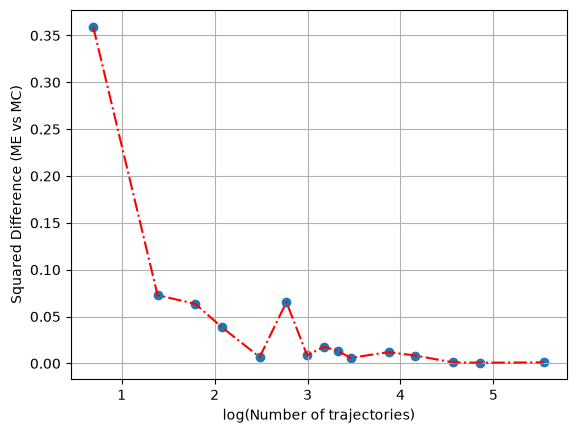

In [33]:
plt.plot(np.log(ntraj_s), sqr_errors, c = "r", ls = "-.")
plt.scatter(np.log(ntraj_s), sqr_errors)

plt.xlabel("log(Number of trajectories)")
plt.ylabel("Squared Difference (ME vs MC)")

plt.grid()
plt.show()